# DRIMA History & Temporal Series Analysis (`matplotlib`)

**DRIMA** (*Dynamics of Randomly Interacting Moving Agents*, Pedro P. B. de Oliveira, *The Mathematica Journal*, 12, 2010) models how reactive agents have their movement behavior modified through local pairwise interactions on a 2D periodic cellular grid.

This notebook loads the simulation output from `history.json`, extracts structured time series, and plots all temporal series and spatial visualizations using **`matplotlib`**:
1. **Movement Pattern Temporal Series (`DisplayHistory` / Figure 2):** Multi-panel `matplotlib` temporal series of the 9 directional probabilities $\{P_E, P_{NE}, P_N, P_{NW}, P_W, P_{SW}, P_S, P_{SE}, X\}$ over $t = 0 \dots N$ for every D-agent and R-agent.
2. **R-Agent Convergence & Determinism Temporal Series:** Evolution of each R-agent's maximum directional probability $\max_d P_d(t)$, normalized determinism score ($1 - H(P)/\log K$), and the population mean convergence curve.
3. **Interaction Dynamics Temporal Series:** Rolling and cumulative interaction counts (total encounters vs. effective pattern-changing interactions) and a pairwise interaction heatmap.
4. **Spatial World Visualization (`DisplayWorld` / Figure 1) & Cell Occupancy:** Color-coded `matplotlib` grid rendering initial ($t=0$) vs. final ($t=N$) world states (yellow background, red D-agents, blue R-agents, as in Figure 1 of the paper) alongside a cell visit frequency heatmap.
5. **Comparative Regime Temporal Series (Figures 2, 3, 4, and 5):** Side-by-side `matplotlib` temporal series comparing standard DRIMA ($F_p=1$, equal-displacement normalization) against high increment factor instability ($F_p=5$), unnormalized dynamics, and proportional normalization stagnation.

## 1. Setup & Loading `history.json`

A DRIMA `history.json` file contains:
- `metadata`: Configuration parameters, total steps, interaction counts, and initial/final convergence metrics.
- `initial_world` & `final_world`: Snapshots of the world at $t = 0$ and $t = N$.
- `history`: Chronological list of snapshots for $t = 0, 1, \dots, N$, where each entry records the world state, per-agent convergence metrics, and step events (`interactions` and `movements`).

In [1]:
import importlib
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

import src.drima.models
import src.drima.grid
import src.drima.normalization
import src.drima.interactions
import src.drima.world
import src.drima.simulation
import src.drima.config
import src.drima.io_handler
import src.drima.analysis

# Reload modules so any already-running Jupyter kernel picks up the latest code
for _mod in (
    src.drima.models,
    src.drima.grid,
    src.drima.normalization,
    src.drima.interactions,
    src.drima.world,
    src.drima.io_handler,
    src.drima.simulation,
    src.drima.config,
    src.drima.analysis,
):
    importlib.reload(_mod)

from src.drima.config import build_simulation_config
from src.drima.simulation import run_simulation
from src.drima.io_handler import load_history_json
from src.drima.models import DIRECTIONS, World
from src.drima.analysis import (
    extract_agent_probability_series,
    extract_convergence_series,
    extract_interaction_series,
    extract_position_series,
)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

HISTORY_PATH = Path("history.json")
if not HISTORY_PATH.exists():
    print("Generating default history.json from examples/figure2_experiment.json...")
    cfg = build_simulation_config(
        config_file="examples/figure2_experiment.json",
        cli_overrides={"iterations": 250, "seed": 42, "output_file": str(HISTORY_PATH)},
    )
    run_simulation(cfg, write_output=True)

history_data = load_history_json(str(HISTORY_PATH))
meta = history_data["metadata"]

print(f"Loaded History File : {HISTORY_PATH.resolve()}")
print(f"Grid Size           : {meta['config']['grid_width']} x {meta['config']['grid_height']} (Mobility: {meta['config']['world_mobility']})")
print(f"Interaction Types   : {meta['config']['interaction_types']} (Range R={meta['config']['interaction_range']})")
print(f"Update & Delta Mode : {meta['config']['update_mode']} | {meta['config']['delta_mode']} (F_p={meta['config']['fp']})")
print(f"Total Steps         : {meta['total_steps']} ({meta['total_snapshots']} snapshots)")
print(f"Total Interactions  : {meta['total_interactions']} (Effective: {meta['effective_interactions']})")
print(f"Mean R Max-Prob     : {meta['initial_convergence']['r_mean_max_prob']:.4f} -> {meta['final_convergence']['r_mean_max_prob']:.4f}")

Loaded History File : /Users/cauesantana/Desktop/DRIMA/history.json
Grid Size           : 8 x 5 (Mobility: F)
Interaction Types   : ['dd', 'RR', 'dR', 'Rd'] (Range R=1)
Update & Delta Mode : sync | fixed (F_p=1.0)
Total Steps         : 250 (251 snapshots)
Total Interactions  : 1273 (Effective: 1157)
Mean R Max-Prob     : 0.1250 -> 0.9674


## 2. Building Temporal Series DataFrames

Using `src.drima.analysis`, we extract structured time-series tables in `pandas`:
1. `df_probs`: Long-form DataFrame of directional probabilities $P_d(t)$ for every agent at every step $t$.
2. `df_conv`: Step-level convergence metrics (`r_mean_max_prob`, `r_converged_95_count`, plus per-agent `max_probability` and `determinism_score`).
3. `df_interactions`: Step-level and cumulative interaction counts.

In [2]:
prob_series = extract_agent_probability_series(history_data)
conv_series = extract_convergence_series(history_data)
inter_series = extract_interaction_series(history_data)
pos_series = extract_position_series(history_data)

# 1. Build a tidy DataFrame of directional probabilities over time
prob_rows = []
for agent_name, agent_dict in prob_series.items():
    steps = agent_dict["step"]
    for idx, step in enumerate(steps):
        row = {"step": step, "agent": agent_name, "type": agent_name[0]}
        for d_name in DIRECTIONS:
            row[d_name] = agent_dict[d_name][idx]
        prob_rows.append(row)
df_probs = pd.DataFrame(prob_rows)

# 2. Build a step-level Convergence DataFrame
conv_cols = {
    "step": conv_series["steps"],
    "r_mean_max_prob": conv_series["r_mean_max_prob"],
    "r_converged_95_count": conv_series["r_converged_95_count"],
}
for agent_name, max_probs in conv_series["per_agent_max_prob"].items():
    conv_cols[f"{agent_name}_max_prob"] = max_probs
    conv_cols[f"{agent_name}_determinism"] = conv_series["per_agent_determinism"][agent_name]
    conv_cols[f"{agent_name}_dom_dir"] = conv_series["per_agent_dominant_dir"][agent_name]
df_conv = pd.DataFrame(conv_cols).set_index("step")

# 3. Build an Interaction Activity DataFrame
df_interactions = pd.DataFrame({
    "step": inter_series["steps"],
    "total_interactions": inter_series["total_interactions_per_step"],
    "effective_interactions": inter_series["effective_interactions_per_step"],
    "cumulative_total": inter_series["cumulative_total_interactions"],
    "cumulative_effective": inter_series["cumulative_effective_interactions"],
}).set_index("step")

display(df_conv.head())
display(df_conv.tail())

,r_mean_max_prob,r_converged_95_count,D01_max_prob,D01_determinism,D01_dom_dir,D02_max_prob,D02_determinism,D02_dom_dir,R01_max_prob,R01_determinism,R01_dom_dir,R02_max_prob,R02_determinism,R02_dom_dir,R03_max_prob,R03_determinism,R03_dom_dir,R04_max_prob,R04_determinism,R04_dom_dir,R05_max_prob,R05_determinism,R05_dom_dir,R06_max_prob,R06_determinism,R06_dom_dir
step,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.125000,0,1.0,1.0,SE,1.0,1.0,E,0.125000,0.000000,E,0.125000,0.000000,E,0.125000,0.000000,E,0.125000,0.000000,E,0.125000,0.000000,E,0.125000,0.000000,E
1,0.185764,0,1.0,1.0,SE,1.0,1.0,E,0.125000,0.000000,E,0.210069,0.013590,SE,0.210069,0.013590,SE,0.125000,0.000000,E,0.222222,0.017432,SE,0.222222,0.017432,E
2,0.240958,0,1.0,1.0,SE,1.0,1.0,E,0.296658,0.049434,SE,0.199436,0.010578,SE,0.210069,0.013590,SE,0.210069,0.028261,E,0.210069,0.013590,SE,0.319444,0.061888,E
3,0.287037,0,1.0,1.0,SE,1.0,1.0,E,0.296658,0.049434,SE,0.296658,0.049434,SE,0.210069,0.013590,SE,0.402995,0.135760,E,0.210069,0.013590,SE,0.305773,0.070677,E
4,0.292824,0,1.0,1.0,SE,1.0,1.0,E,0.296658,0.049434,SE,0.296658,0.049434,SE,0.197917,0.024652,E,0.376953,0.170397,E,0.197917,0.024652,E,0.390842,0.126517,E


,r_mean_max_prob,r_converged_95_count,D01_max_prob,D01_determinism,D01_dom_dir,D02_max_prob,D02_determinism,D02_dom_dir,R01_max_prob,R01_determinism,R01_dom_dir,R02_max_prob,R02_determinism,R02_dom_dir,R03_max_prob,R03_determinism,R03_dom_dir,R04_max_prob,R04_determinism,R04_dom_dir,R05_max_prob,R05_determinism,R05_dom_dir,R06_max_prob,R06_determinism,R06_dom_dir
step,,,,,,,,,,,,,,,,,,,,,,,,,,
246,0.971753,4,1.0,1.0,SE,1.0,1.0,E,0.947637,0.901216,E,0.982428,0.957472,SE,0.974401,0.942729,E,0.987201,0.967058,E,0.991214,0.975788,SE,0.947637,0.901216,E
247,0.975549,4,1.0,1.0,SE,1.0,1.0,E,0.947637,0.901216,E,0.991214,0.975788,SE,0.990401,0.973958,E,0.980801,0.954360,E,0.995607,0.986425,SE,0.947637,0.901216,E
248,0.977882,6,1.0,1.0,SE,1.0,1.0,E,0.958328,0.916698,E,0.995607,0.986425,SE,0.969019,0.933570,E,0.990401,0.973958,E,0.995607,0.986425,SE,0.958328,0.916698,E
249,0.961420,3,1.0,1.0,SE,1.0,1.0,E,0.930550,0.878711,E,0.940051,0.890920,SE,0.989855,0.972749,E,0.979710,0.952311,E,0.997803,0.992479,SE,0.930550,0.878711,E
250,0.967444,4,1.0,1.0,SE,1.0,1.0,E,0.930550,0.878711,E,0.970026,0.935246,SE,0.987319,0.967304,E,0.987319,0.967304,E,0.998902,0.995873,SE,0.930550,0.878711,E


## 3. Temporal Series Plot 1: Evolution of Agent Movement Patterns (`DisplayHistory` / Figure 2)

In **Figure 2** of de Oliveira (2010), each subplot shows the temporal evolution of the 9 directional probabilities $P_d(t)$ for an individual agent:
- **D-agents (`D01`, `D02`):** Remain constant at $P_d(t) = 1.0$ in their fixed direction (and $0.0$ in all other directions).
- **R-agents (`R01`..`R06`):** Start uniformly ($0.125$ in all 8 compass directions under Full mobility `F`). As they interact with D-agents and with each other, **equal-displacement normalization** drives the 6 unfavored directions down to $0.0$, while the two attractor directions (`E` and `SE`) compete until one prevails.

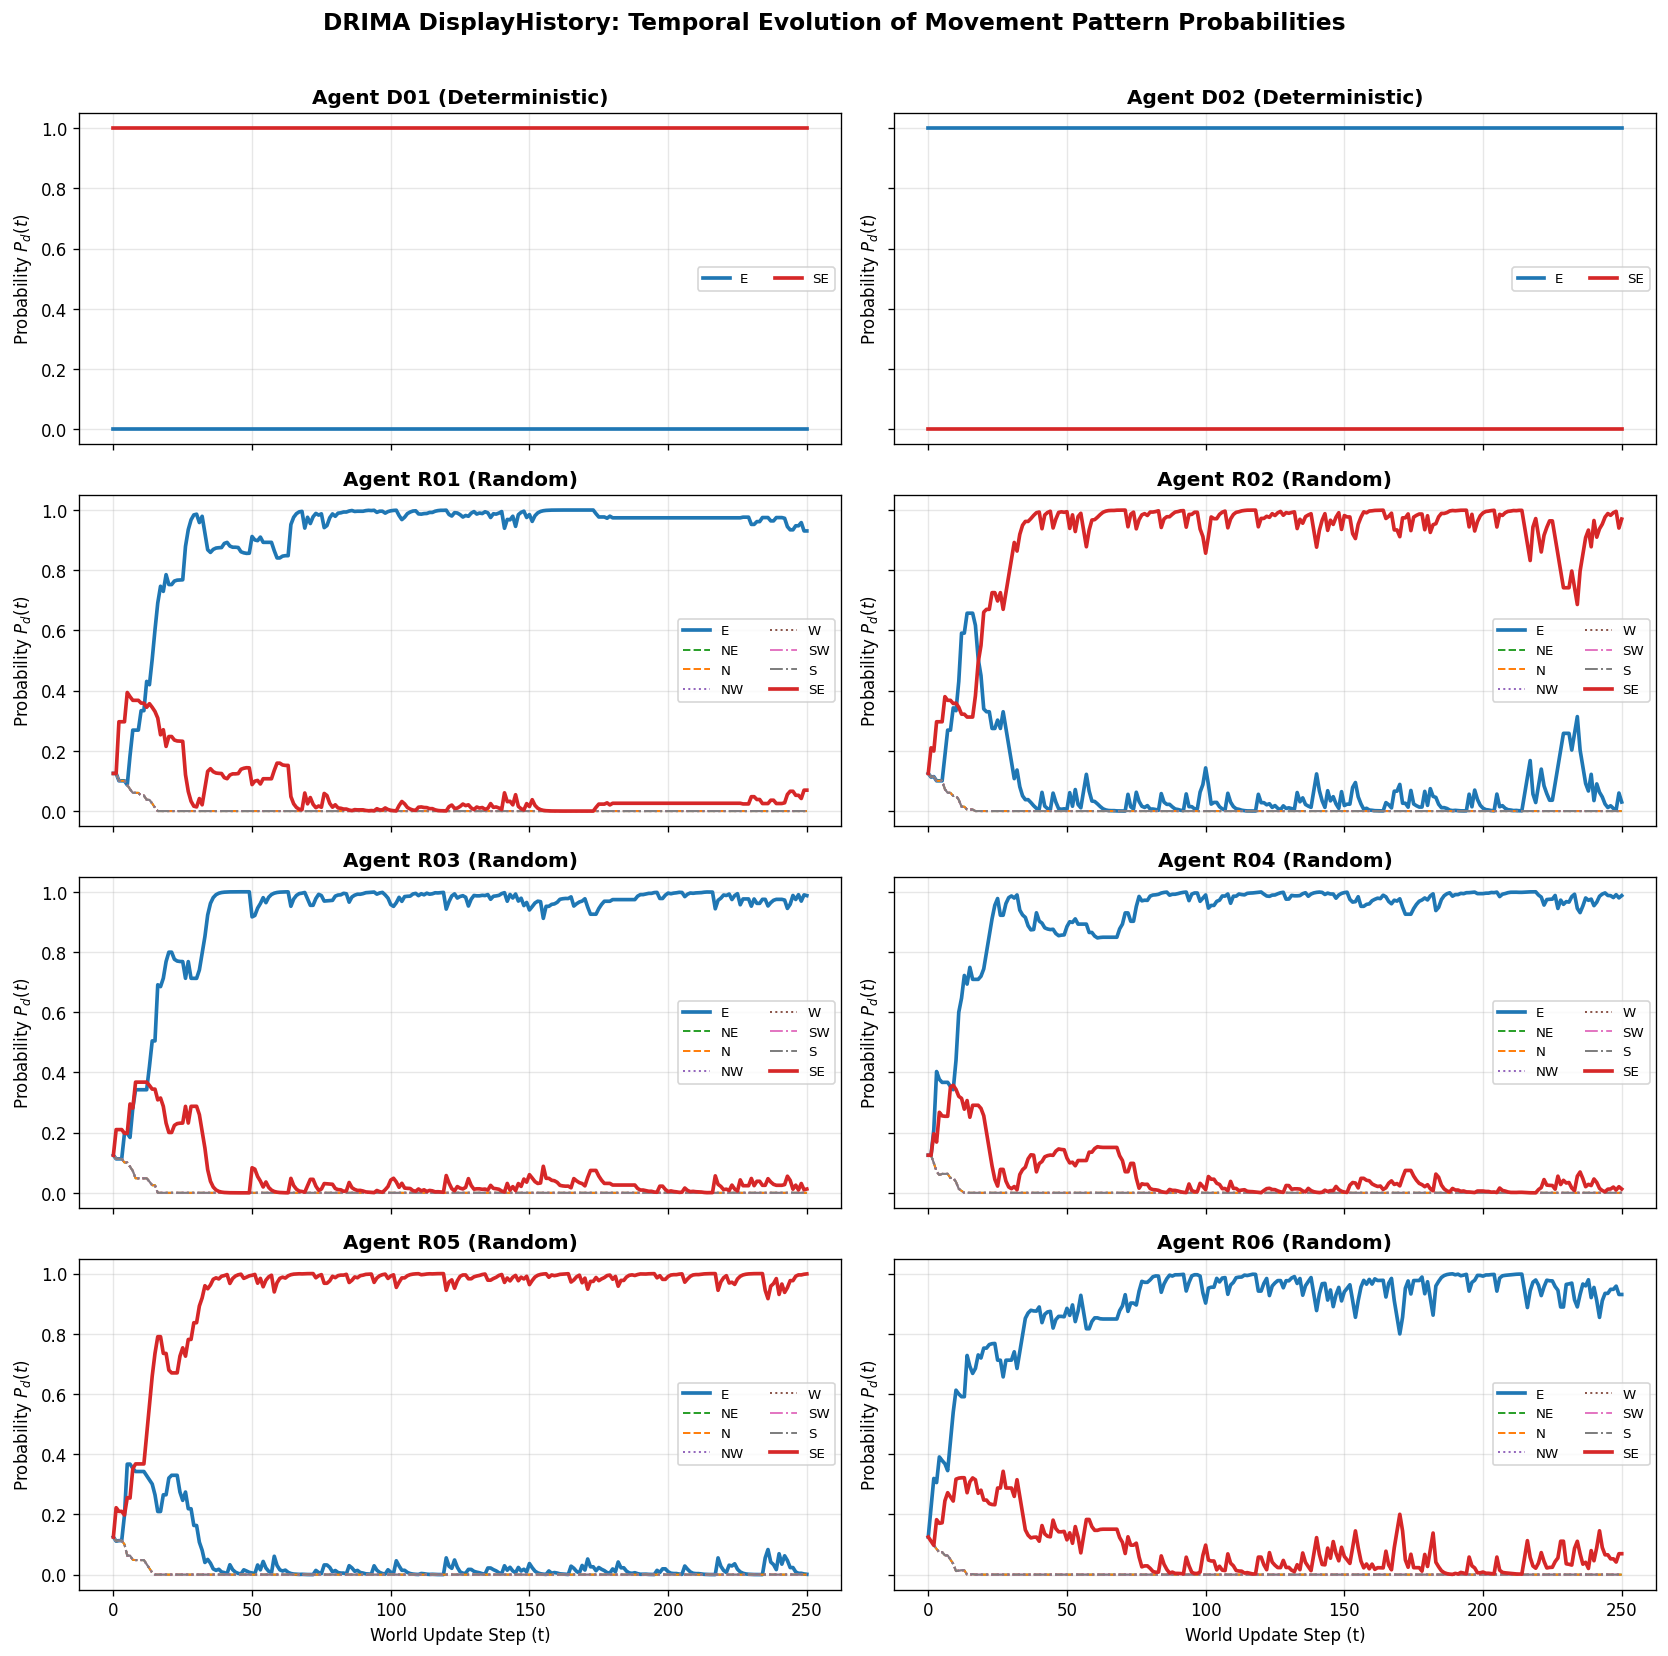

In [3]:
def plot_agent_movement_temporal_series(prob_series_dict, agent_names=None):
    """Plot the 9 directional probability time series for each selected agent using matplotlib."""
    names = list(agent_names) if agent_names else list(prob_series_dict.keys())
    n_agents = len(names)
    n_cols = 2
    n_rows = (n_agents + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.4 * n_rows), sharex=True, sharey=True)
    axes_flat = np.array(axes).reshape(-1)

    dir_styles = {
        "E": ("#1f77b4", "-", 2.2),
        "SE": ("#d62728", "-", 2.2),
        "NE": ("#2ca02c", "--", 1.2),
        "N": ("#ff7f0e", "--", 1.2),
        "NW": ("#9467bd", ":", 1.2),
        "W": ("#8c564b", ":", 1.2),
        "SW": ("#e377c2", "-.", 1.2),
        "S": ("#7f7f7f", "-.", 1.2),
        "X": ("#000000", ":", 1.0),
    }

    for idx, name in enumerate(names):
        ax = axes_flat[idx]
        agent_data = prob_series_dict[name]
        steps = agent_data["step"]
        for d_name in DIRECTIONS:
            vals = agent_data[d_name]
            if max(vals) > 0.001 or d_name in ("E", "SE"):
                color, ls, lw = dir_styles[d_name]
                ax.plot(steps, vals, label=d_name, color=color, linestyle=ls, linewidth=lw)
        role = "Deterministic" if name.startswith("D") else "Random"
        ax.set_title(f"Agent {name} ({role})", fontweight="bold")
        ax.set_ylim(-0.05, 1.05)
        ax.set_ylabel("Probability $P_d(t)$")
        if idx >= n_agents - n_cols:
            ax.set_xlabel("World Update Step (t)")
        ax.legend(loc="center right", ncol=2, fontsize=8)

    for extra_idx in range(n_agents, len(axes_flat)):
        axes_flat[extra_idx].set_visible(False)

    fig.suptitle(
        "DRIMA DisplayHistory: Temporal Evolution of Movement Pattern Probabilities",
        fontsize=14,
        fontweight="bold",
        y=1.01,
    )
    plt.tight_layout()
    plt.show()

plot_agent_movement_temporal_series(prob_series)

## 4. Temporal Series Plot 2: R-Agent Convergence & Entropy Reduction

To quantify how quickly R-agents transition from uniform randomness ($\max_d P_d = 0.125$ in Full mobility) to deterministic behavior ($\max_d P_d \to 1.0$), we plot two temporal series:
1. **Maximum Directional Probability ($\max_d P_d(t)$):** Measures commitment to the single strongest direction at step $t$.
2. **Determinism Score ($1 - H(P_t) / \log K$):** Derived from normalized Shannon entropy, where $0.0$ is completely uniform random movement across all $K$ allowed directions and $1.0$ is purely deterministic movement in a single direction.

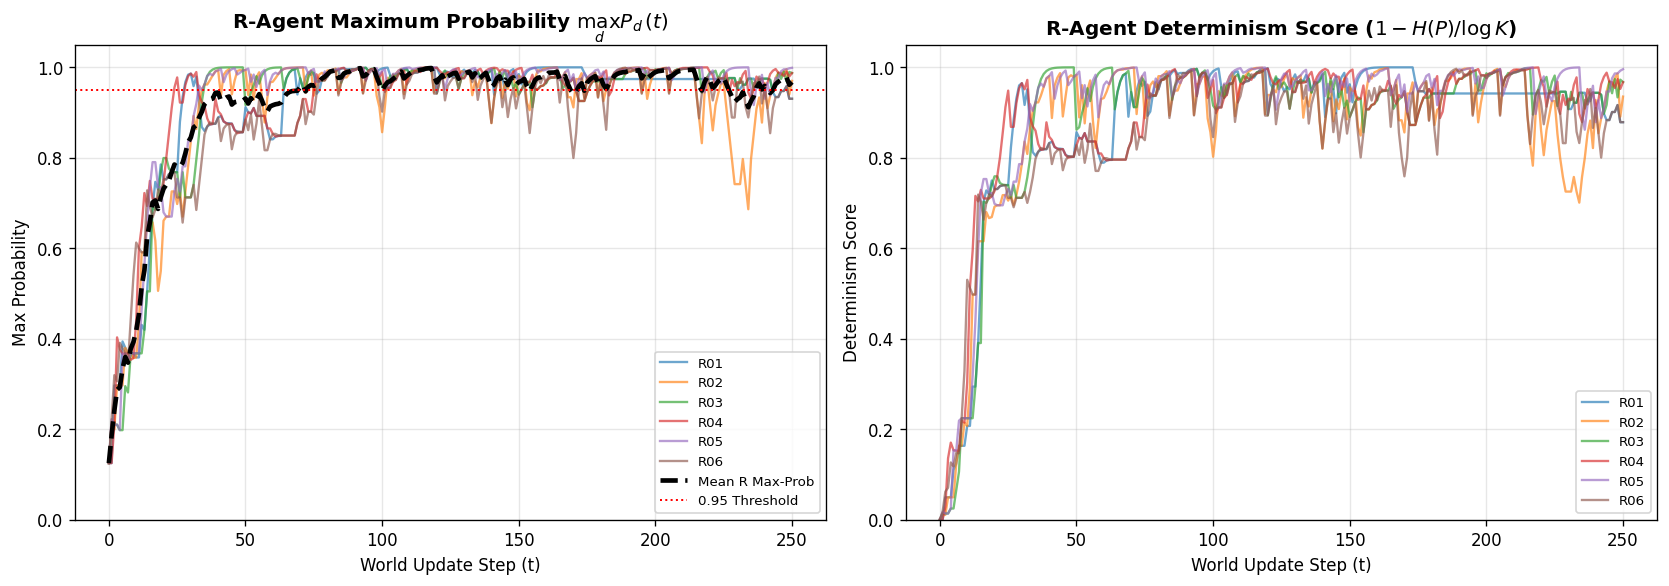

In [4]:
r_agent_names = [name for name in prob_series if name.startswith("R")]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for r_name in r_agent_names:
    ax1.plot(df_conv.index, df_conv[f"{r_name}_max_prob"], alpha=0.65, linewidth=1.4, label=r_name)
    ax2.plot(df_conv.index, df_conv[f"{r_name}_determinism"], alpha=0.65, linewidth=1.4, label=r_name)

ax1.plot(
    df_conv.index,
    df_conv["r_mean_max_prob"],
    color="black",
    linewidth=2.8,
    linestyle="--",
    label="Mean R Max-Prob",
)
ax1.axhline(0.95, color="red", linestyle=":", linewidth=1.2, label="0.95 Threshold")
ax1.set_title("R-Agent Maximum Probability $\\max_d P_d(t)$", fontweight="bold")
ax1.set_xlabel("World Update Step (t)")
ax1.set_ylabel("Max Probability")
ax1.set_ylim(0.0, 1.05)
ax1.legend(loc="lower right", fontsize=8)

ax2.set_title("R-Agent Determinism Score ($1 - H(P)/\\log K$)", fontweight="bold")
ax2.set_xlabel("World Update Step (t)")
ax2.set_ylabel("Determinism Score")
ax2.set_ylim(0.0, 1.05)
ax2.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

## 5. Temporal Series Plot 3: Interaction Frequency & Pairwise Influence Matrix

### Addressing a Common Confusion: Total vs. Effective Interactions
- **What NOT to assume:** Do not assume every binary encounter alters an agent's movement pattern.
- **Why:** When `interaction_types` is `["dd", "RR", "dR", "Rd"]`, two D-agents meeting (`dd`) never change each other's movement pattern, and two agents that have already converged to identical movement patterns produce $\Delta p = 0$ (or clamped zero change). Comparing `total_interactions` vs. `effective_interactions` over time reveals when the system is actively reorganizing vs. when local neighborhoods have equilibrated.

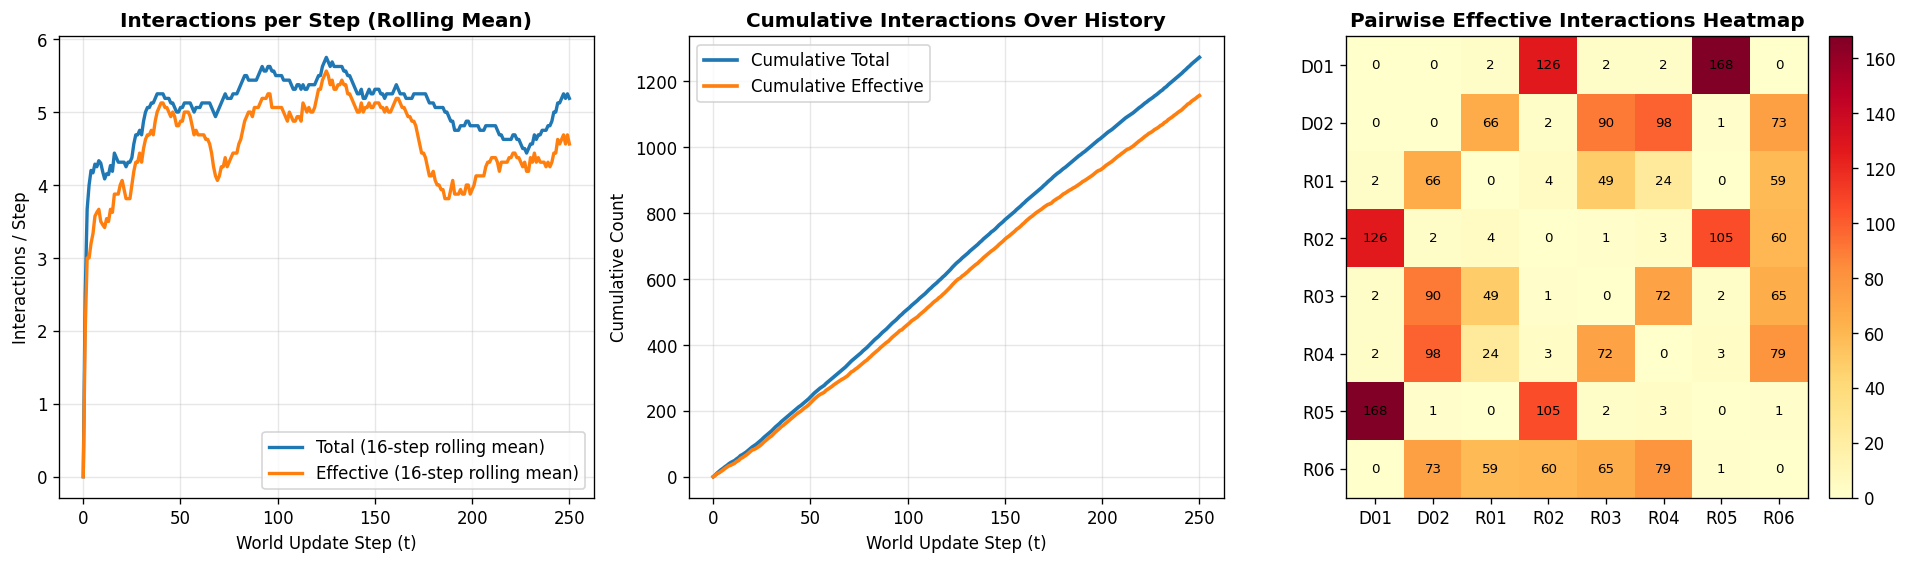

In [5]:
agent_names = inter_series["agent_names"]
matrix_data = np.zeros((len(agent_names), len(agent_names)), dtype=int)
for i, a_i in enumerate(agent_names):
    for j, a_j in enumerate(agent_names):
        matrix_data[i, j] = inter_series["pairwise_effective_matrix"].get((a_i, a_j), 0)

df_pairwise = pd.DataFrame(matrix_data, index=agent_names, columns=agent_names)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Rolling interaction rate per step
window = max(1, len(df_interactions) // 15)
ax1.plot(
    df_interactions.index,
    df_interactions["total_interactions"].rolling(window, min_periods=1).mean(),
    label=f"Total ({window}-step rolling mean)",
    color="#1f77b4",
    linewidth=2,
)
ax1.plot(
    df_interactions.index,
    df_interactions["effective_interactions"].rolling(window, min_periods=1).mean(),
    label=f"Effective ({window}-step rolling mean)",
    color="#ff7f0e",
    linewidth=2,
)
ax1.set_title("Interactions per Step (Rolling Mean)", fontweight="bold")
ax1.set_xlabel("World Update Step (t)")
ax1.set_ylabel("Interactions / Step")
ax1.legend()

# 2. Cumulative interactions over time
ax2.plot(
    df_interactions.index,
    df_interactions["cumulative_total"],
    label="Cumulative Total",
    color="#1f77b4",
    linewidth=2.2,
)
ax2.plot(
    df_interactions.index,
    df_interactions["cumulative_effective"],
    label="Cumulative Effective",
    color="#ff7f0e",
    linewidth=2.2,
)
ax2.set_title("Cumulative Interactions Over History", fontweight="bold")
ax2.set_xlabel("World Update Step (t)")
ax2.set_ylabel("Cumulative Count")
ax2.legend()

# 3. Heatmap of pairwise effective interactions
im = ax3.imshow(df_pairwise.values, cmap="YlOrRd")
ax3.set_xticks(range(len(agent_names)))
ax3.set_yticks(range(len(agent_names)))
ax3.set_xticklabels(agent_names)
ax3.set_yticklabels(agent_names)
ax3.set_title("Pairwise Effective Interactions Heatmap", fontweight="bold")
ax3.grid(False)
for i in range(len(agent_names)):
    for j in range(len(agent_names)):
        ax3.text(j, i, str(df_pairwise.values[i, j]), ha="center", va="center", color="black", fontsize=8)
fig.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 6. Spatial Grid Visualization (`DisplayWorld` / Figure 1) & Cell Visit Heatmap

In **Figure 1** of de Oliveira (2010), the DRIMA world is rendered with:
- **Yellow background** for empty cells,
- **Red cells** for deterministic D-agents,
- **Blue cells** for random R-agents (with agent tags and dominant movement arrows).

Below we plot the initial ($t = 0$) and final ($t = N$) world grids alongside a heatmap of cumulative cell visits across the simulation.

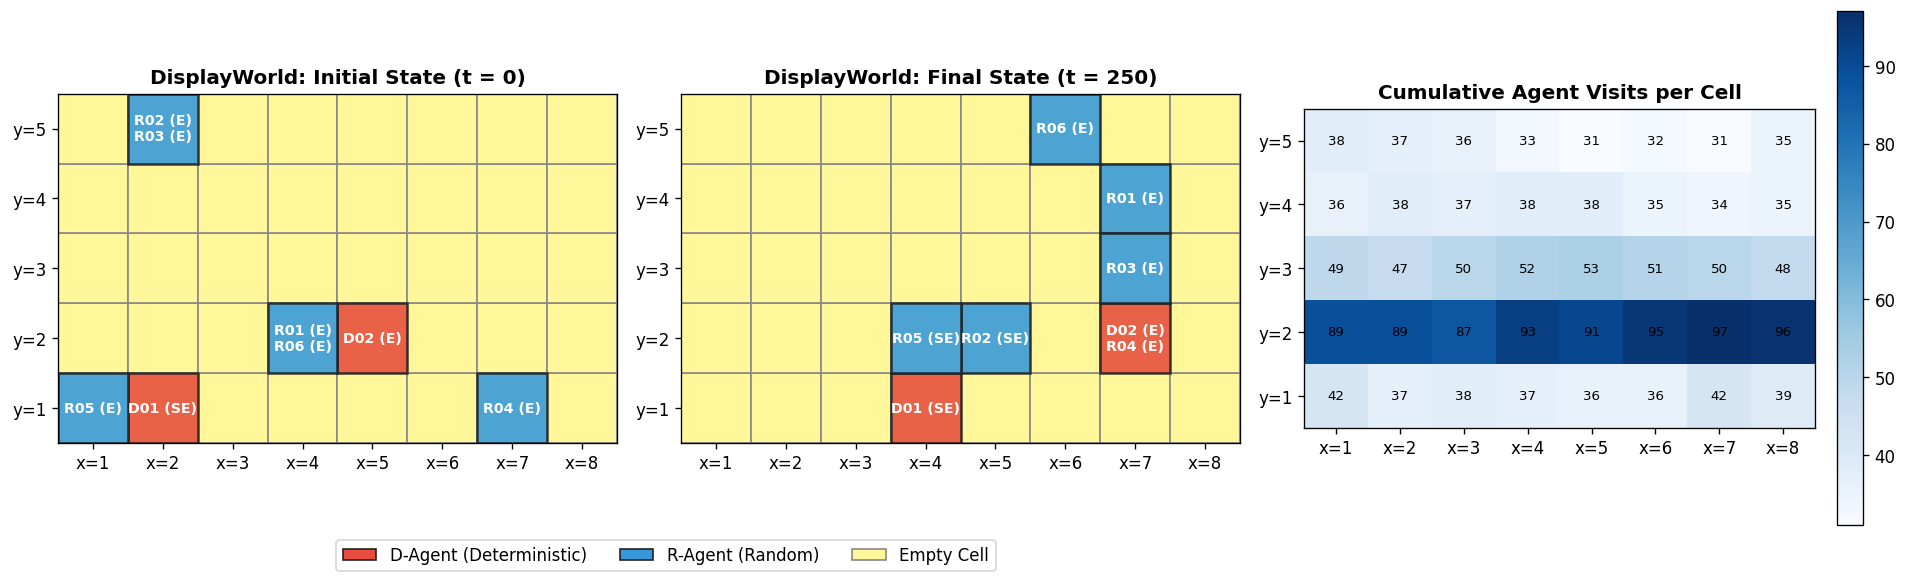

In [6]:
def plot_drima_world_ax(ax, world_obj, title):
    """Render a DRIMA World on a matplotlib Axes matching Figure 1 of the paper."""
    x_max, y_max = world_obj.grid_size
    ax.set_xlim(0.5, x_max + 0.5)
    ax.set_ylim(0.5, y_max + 0.5)
    ax.set_xticks(range(1, x_max + 1))
    ax.set_yticks(range(1, y_max + 1))
    ax.set_xticklabels([f"x={x}" for x in range(1, x_max + 1)])
    ax.set_yticklabels([f"y={y}" for y in range(1, y_max + 1)])
    ax.set_aspect("equal")
    ax.grid(False)

    # Draw yellow background grid cells
    for x in range(1, x_max + 1):
        for y in range(1, y_max + 1):
            rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor="#fff799", edgecolor="#888888", linewidth=1.0)
            ax.add_patch(rect)

    cell_agents = {}
    for agent in world_obj.agents:
        cell_agents.setdefault(agent.position, []).append(agent)

    for (x, y), agents_in_cell in cell_agents.items():
        has_d = any(a.agent_type == "D" for a in agents_in_cell)
        color = "#e74c3c" if has_d else "#3498db"
        rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=color, edgecolor="#222222", linewidth=1.5, alpha=0.88)
        ax.add_patch(rect)
        label = "\n".join(f"{a.name} ({a.dominant_direction})" for a in agents_in_cell)
        ax.text(x, y, label, ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)

    ax.set_title(title, fontweight="bold")

initial_world = World.from_dict(history_data["initial_world"])
final_world = World.from_dict(history_data["final_world"])

x_max, y_max = initial_world.grid_size
visit_counts = np.zeros((y_max, x_max), dtype=int)
for agent_name, coords in pos_series.items():
    for (x, y) in coords:
        visit_counts[y - 1, x - 1] += 1

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8))
plot_drima_world_ax(ax1, initial_world, "DisplayWorld: Initial State (t = 0)")
plot_drima_world_ax(ax2, final_world, f"DisplayWorld: Final State (t = {meta['total_steps']})")

im = ax3.imshow(visit_counts, origin="lower", cmap="Blues", extent=[0.5, x_max + 0.5, 0.5, y_max + 0.5])
ax3.set_xticks(range(1, x_max + 1))
ax3.set_yticks(range(1, y_max + 1))
ax3.set_xticklabels([f"x={x}" for x in range(1, x_max + 1)])
ax3.set_yticklabels([f"y={y}" for y in range(1, y_max + 1)])
ax3.set_title("Cumulative Agent Visits per Cell", fontweight="bold")
ax3.grid(False)
for y_idx in range(y_max):
    for x_idx in range(x_max):
        ax3.text(x_idx + 1, y_idx + 1, str(visit_counts[y_idx, x_idx]), ha="center", va="center", color="black", fontsize=8)
fig.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)

legend_patches = [
    Patch(facecolor="#e74c3c", edgecolor="#222", label="D-Agent (Deterministic)"),
    Patch(facecolor="#3498db", edgecolor="#222", label="R-Agent (Random)"),
    Patch(facecolor="#fff799", edgecolor="#888", label="Empty Cell"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=3, bbox_to_anchor=(0.35, -0.04))
plt.tight_layout()
plt.show()

## 7. Comparative Regime Temporal Series: Probing DRIMA Parameters (Figures 2, 3, 4, and 5)

In Section 3.2 of the paper, de Oliveira demonstrates why DRIMA's specific design choices are essential for rich emergent dynamics:
1. **Standard DRIMA ($F_p = 1.0$, `equal_displacement` normalization — Figure 2):** Fast, decisive convergence where R-agents commit to one of the D-agent directions.
2. **High Increment Factor ($F_p = 5.0$, `variable` mode — Figure 3):** Rapid jumps cause persistent instability and sharp oscillations whenever an R-agent passes near a competing D-agent.
3. **No Normalization (`none` — Figure 4):** R-agents accumulate probability $1.0$ in *both* D-agent directions simultaneously, violating probability axioms ($\sum_d P_d > 1$).
4. **Proportional Normalization (`proportional` — Figure 5):** R-agents flatten out around $\approx 0.50$ probability in each D-agent direction without ever resolving toward a single choice.

,R01 Final P(E),R01 Final P(SE),R01 Final Sum(P),Mean R Max-Prob
Regime,,,,
"Fig 2: F_p=1.0, Equal-Displacement",0.9741,0.0259,1.00,0.989331
"Fig 3: F_p=5.0, Variable (Instability)",0.2663,0.7337,1.00,0.785360
"Fig 4: F_p=1.0, No Normalization",1.0000,1.0000,2.75,1.000000
"Fig 5: F_p=1.0, Proportional Norm",0.2830,0.6959,1.00,0.818532


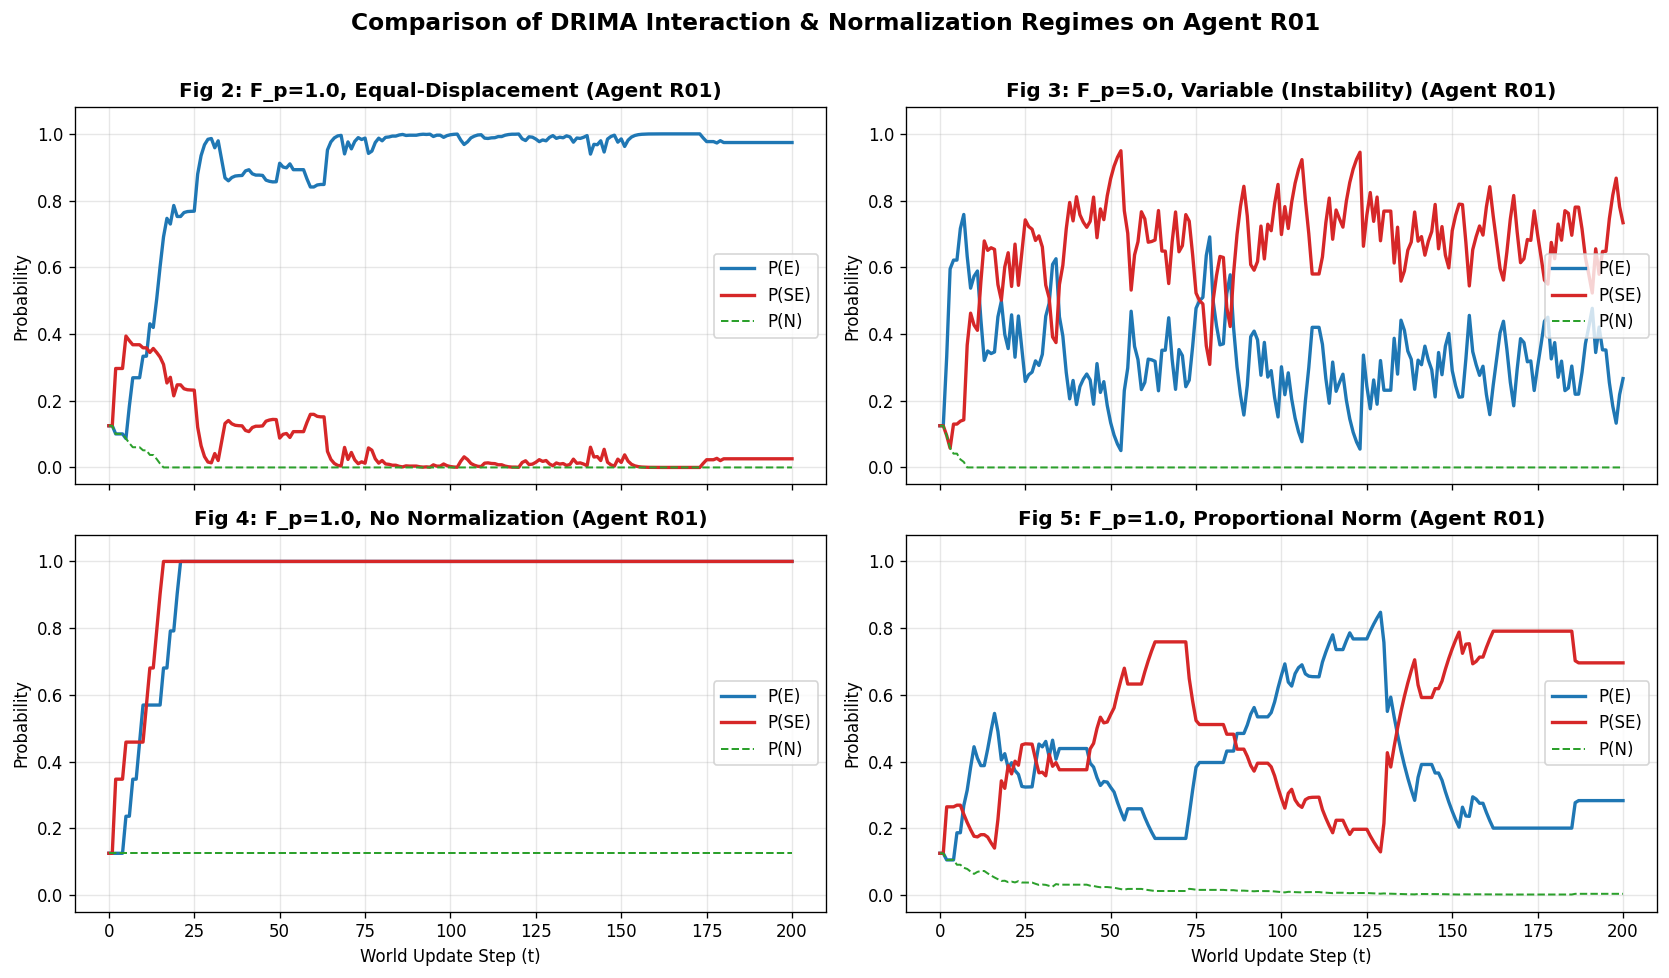

In [7]:
regimes = {
    "Fig 2: F_p=1.0, Equal-Displacement": {
        "fp": 1.0,
        "delta_mode": "fixed",
        "normalization_method": "equal_displacement",
    },
    "Fig 3: F_p=5.0, Variable (Instability)": {
        "fp": 5.0,
        "delta_mode": "variable",
        "normalization_method": "equal_displacement",
    },
    "Fig 4: F_p=1.0, No Normalization": {
        "fp": 1.0,
        "delta_mode": "fixed",
        "normalization_method": "none",
    },
    "Fig 5: F_p=1.0, Proportional Norm": {
        "fp": 1.0,
        "delta_mode": "fixed",
        "normalization_method": "proportional",
    },
}

comparison_rows = []
regime_prob_histories = {}

for label, overrides in regimes.items():
    cfg = build_simulation_config(
        config_file="examples/figure2_experiment.json",
        cli_overrides={**overrides, "iterations": 200, "seed": 42, "log_file": None},
    )
    res = run_simulation(cfg, write_output=False)
    p_series = extract_agent_probability_series(res.payload)
    regime_prob_histories[label] = p_series

    r01_e_final = p_series["R01"]["E"][-1]
    r01_se_final = p_series["R01"]["SE"][-1]
    r01_sum_final = sum(p_series["R01"][d][-1] for d in DIRECTIONS)
    comparison_rows.append({
        "Regime": label,
        "R01 Final P(E)": round(r01_e_final, 4),
        "R01 Final P(SE)": round(r01_se_final, 4),
        "R01 Final Sum(P)": round(r01_sum_final, 4),
        "Mean R Max-Prob": res.payload["metadata"]["final_convergence"]["r_mean_max_prob"],
    })

df_regimes = pd.DataFrame(comparison_rows).set_index("Regime")
display(df_regimes)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
axes_flat = axes.reshape(-1)
for idx, (label, p_series) in enumerate(regime_prob_histories.items()):
    ax = axes_flat[idx]
    steps = p_series["R01"]["step"]
    ax.plot(steps, p_series["R01"]["E"], label="P(E)", color="#1f77b4", linewidth=2.0)
    ax.plot(steps, p_series["R01"]["SE"], label="P(SE)", color="#d62728", linewidth=2.0)
    ax.plot(steps, p_series["R01"]["N"], label="P(N)", color="#2ca02c", linestyle="--", linewidth=1.2)
    ax.set_title(f"{label} (Agent R01)", fontweight="bold")
    ax.set_ylim(-0.05, 1.08)
    ax.set_ylabel("Probability")
    if idx >= 2:
        ax.set_xlabel("World Update Step (t)")
    ax.legend(loc="center right")

plt.suptitle(
    "Comparison of DRIMA Interaction & Normalization Regimes on Agent R01",
    fontsize=14,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()